# Notebook 02 — Exploratory Data Analysis and Data Quality

**Project:** Next-Day Wildfire Spread Prediction via Tabular ML and Spatial Deep Learning  
**Team:** TensorTitans, Section C  
**Contributor:** Tejas

## Objective

The goal of this notebook is to understand the wildfire dataset before training machine learning models. We will explore wildfire patterns, environmental conditions, and relationships between input features using simple visualizations.

### What We Will Explore
1. **Wildfire Patch Visualization:** Understand how fire spreads across a spatial grid.
2. **Environmental Feature Distributions:** Examine temperature, humidity, wind speed, and other environmental variables.
3. **Feature Correlation:** Identify relationships between environmental features.
4. **Burned vs. Unburned Comparison:** Compare environmental conditions associated with burned and unburned pixels.
5. **Data Quality:** Check for missing values and inconsistencies.

### Expected Outcome

These visualizations will help us understand the dataset, identify useful features, and prepare for the next stages of wildfire spread prediction.

In [20]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("..")

import src.data_loader as dl

# Create a folder to save graphs
os.makedirs("../results/figures", exist_ok=True)

# Load a sample of wildfire data
tabular_df = dl.extract_split_tabular(
    "train",
    max_patches=15,
    sample_negatives_ratio=10.0
)

print("Dataset shape:", tabular_df.shape)
print("\nFirst five rows:")
display(tabular_df.head())

Dataset shape: (36079, 20)

First five rows:


,patch_id,row,col,dist_to_center,elevation,th,vs,tmmn,tmmx,sph,pr,pdsi,NDVI,population,erc,PrevFireMask,FireMask,fire_neighbor_3x3_sum,fire_neighbor_5x5_sum,split
0,train_0,17,2,1.048157,110.0,178.492386,3.070760,275.707458,293.004242,0.004699,0.0,3.863418,7376.0,0.156175,20.966082,0.0,1.0,0.0,0.0,train
1,train_0,17,3,1.020302,115.0,178.062057,3.064579,275.663116,293.011108,0.004703,0.0,3.930680,7675.0,0.787947,20.775835,0.0,1.0,0.0,0.0,train
2,train_0,17,4,0.992649,113.0,177.624466,3.058788,275.618347,293.019867,0.004707,0.0,3.994039,7360.0,1.546292,20.582205,0.0,1.0,0.0,0.0,train
3,train_0,18,1,1.062959,97.0,179.427567,3.074451,275.724030,293.011719,0.004698,0.0,3.772116,7638.0,0.479190,21.172615,0.0,1.0,0.0,0.0,train
4,train_0,18,2,1.034559,96.0,178.994476,3.067611,275.683197,293.018677,0.004702,0.0,3.838249,7992.0,0.000000,20.989607,0.0,1.0,0.0,0.0,train


### 3. Wildfire Mask Visualization

**Why are we making this graph?**

Before predicting wildfire spread, we need to understand how fire is represented in our dataset. The `FireMask` identifies the target fire conditions, while `PrevFireMask` represents the previous fire conditions.

Visualizing these masks helps us understand the spatial distribution of fire and identify areas that may be relevant to predicting future wildfire spread.

**Expected insight:** The visualization reveals the spatial pattern of fire-labelled pixels across the selected patch. It also helps us inspect whether the previous and target fire masks contain meaningful spatial patterns.

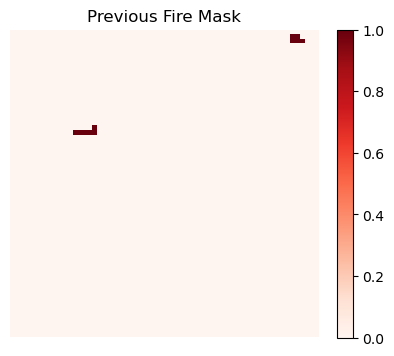

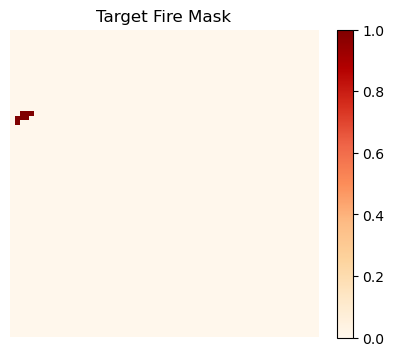

In [21]:
# Find a patch containing fire pixels
active_patch = None

for patch in dl.iter_records(dl.get_tfrecord_paths("train"), max_records=15):
    if np.sum(patch["FireMask"] == 1.0) > 0:
        active_patch = patch
        break

# Check whether a suitable patch was found
if active_patch is None:
    print("No wildfire patches found. Check your dataset path.")
else:
    # Previous fire mask
    plt.figure(figsize=(5, 4))
    plt.imshow(active_patch["PrevFireMask"], cmap="Reds")
    plt.title("Previous Fire Mask")
    plt.colorbar()
    plt.axis("off")
    plt.show()

    # Target fire mask
    plt.figure(figsize=(5, 4))
    plt.imshow(active_patch["FireMask"], cmap="OrRd")
    plt.title("Target Fire Mask")
    plt.colorbar()
    plt.axis("off")
    plt.show()

### Key Insights

- **Sparse Fire Distribution:** Both masks contain mostly unburned pixels, with only a few fire-labelled pixels visible in the selected patch.
- **Previous Fire Mask:** Fire pixels appear in two separate locations, indicating a scattered spatial distribution of previously observed fire.
- **Target Fire Mask:** Fire pixels appear clustered near the left edge of the patch, showing a different spatial pattern from the previous mask.
- **Research Implication:** These spatial patterns highlight the importance of considering previous fire conditions when predicting next-day wildfire spread. The sparse distribution also suggests that class imbalance may be an important challenge for our prediction models.

### 4. Environmental Feature Distributions

**Why are we making these graphs?**

Wildfire spread is influenced by environmental conditions such as temperature, humidity, wind speed, elevation, and vegetation.

We visualize the distributions of eight environmental features to understand their ranges, identify skewed distributions, and detect potential outliers.

**Features analyzed:**
- `tmmx` — Maximum temperature
- `tmmn` — Minimum temperature
- `sph` — Specific humidity
- `vs` — Wind speed
- `elevation` — Terrain elevation
- `erc` — Energy Release Component
- `NDVI` — Vegetation index
- `pdsi` — Drought index

**Expected outcome:** Understand the distribution and variability of environmental conditions in the sampled wildfire dataset.

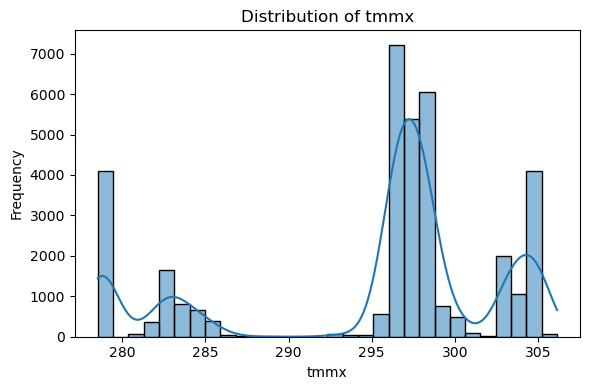

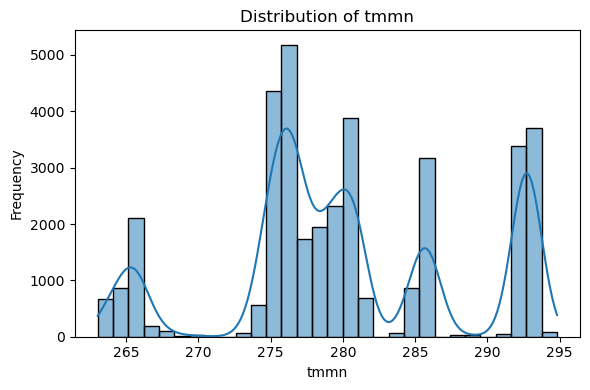

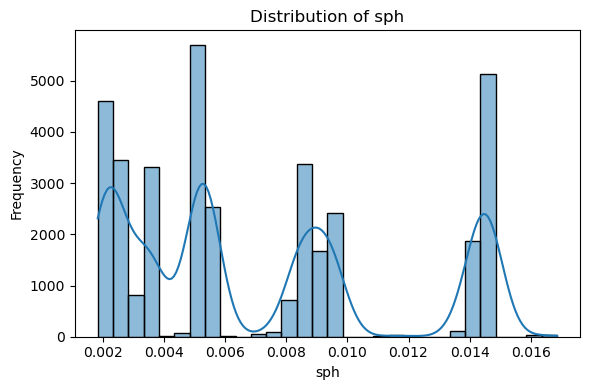

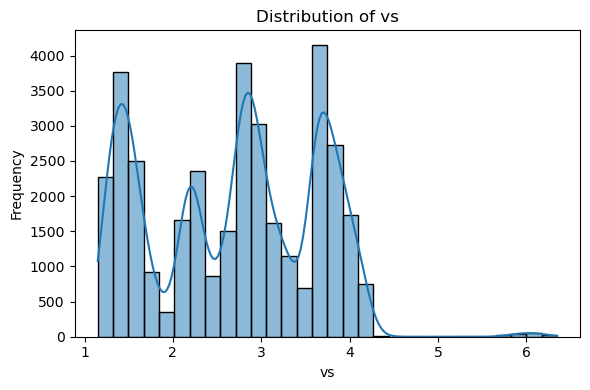

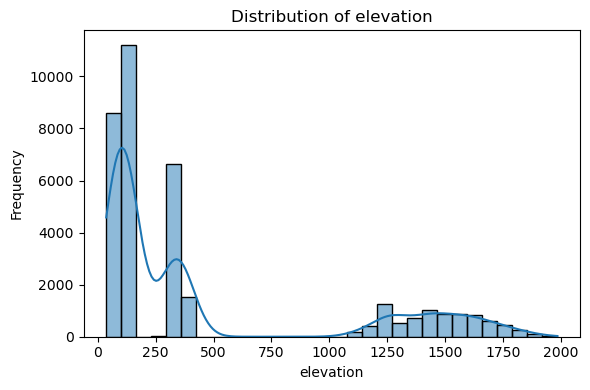

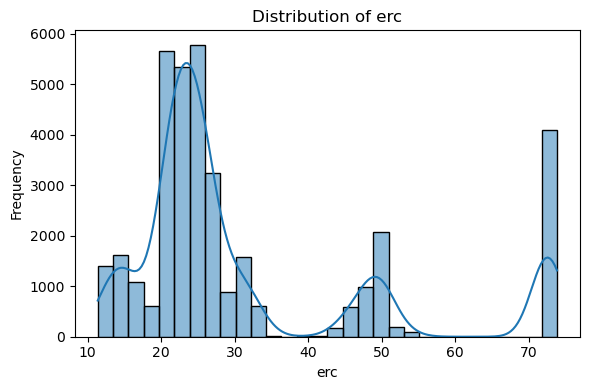

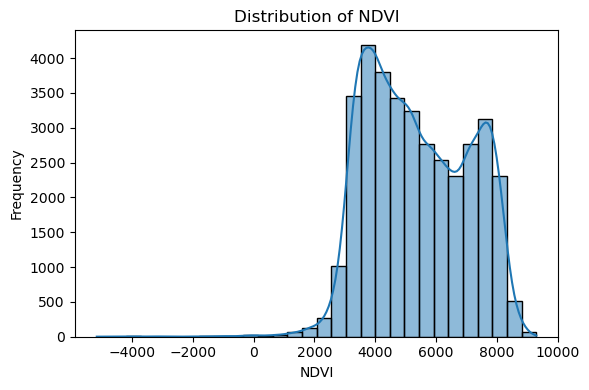

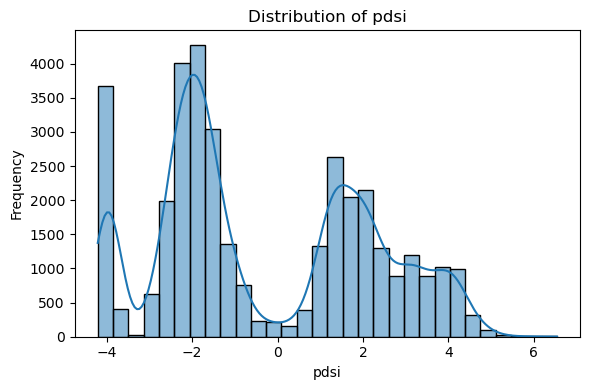

In [22]:
features = ["tmmx", "tmmn", "sph", "vs",
            "elevation", "erc", "NDVI", "pdsi"]

for feature in features:
    plt.figure(figsize=(6, 4))

    sns.histplot(
        data=tabular_df,
        x=feature,
        bins=30,
        kde=True
    )

    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Frequency")
    plt.tight_layout()

    plt.savefig(
        f"../results/figures/{feature}_distribution.png",
        dpi=200
    )

    plt.show()
    plt.close()

- **Temperature:** Multiple peaks indicate varying temperature conditions across sampled regions.
- **Humidity:** Values cluster across distinct ranges, reflecting differences in atmospheric moisture.
- **Wind Speed:** Most observations lie between 1–4 m/s.
- **Elevation:** Samples are concentrated at lower elevations, with a smaller group at higher altitudes.
- **ERC:** Multiple peaks indicate variability in fuel-related fire potential.
- **NDVI:** Extreme negative values warrant checking for scaling or data-quality issues.
- **PDSI:** Multiple peaks reflect variation in drought conditions.

**Conclusion:** Environmental features show substantial variability, highlighting the need for data-quality checks and feature analysis before wildfire prediction.

### 5. Correlation Between Environmental Features

A correlation heatmap helps identify relationships between environmental variables and detect potentially redundant features. This analysis supports feature selection for wildfire spread prediction.

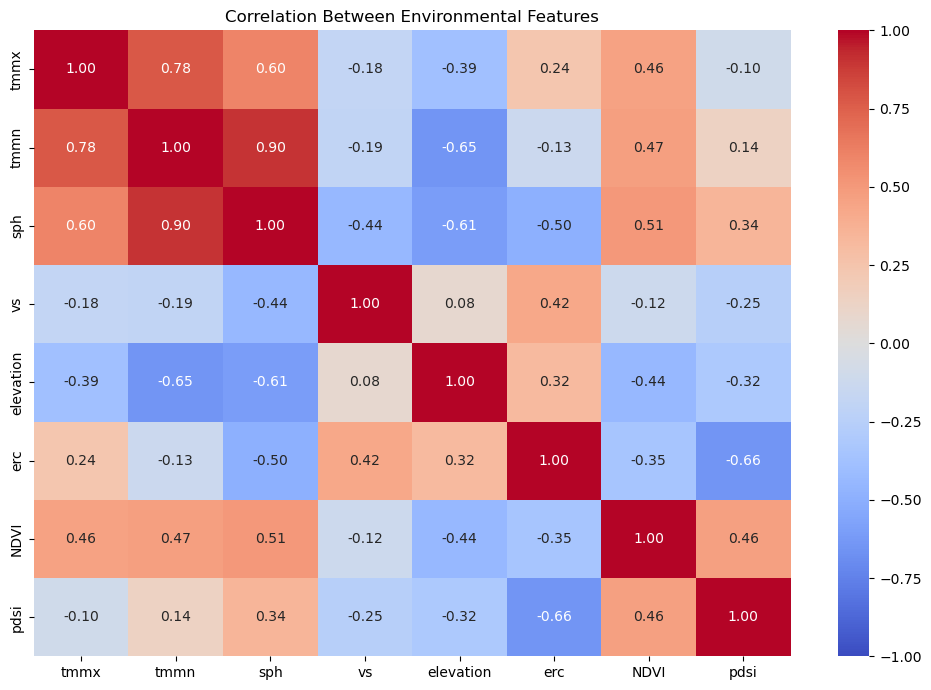

In [23]:
features = [
    "tmmx", "tmmn", "sph", "vs",
    "elevation", "erc", "NDVI", "pdsi"
]

plt.figure(figsize=(10, 7))

correlation = tabular_df[features].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Environmental Features")
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, "correlation_heatmap.png"), dpi=250)
plt.show()
plt.close()

- **Temperature:** `tmmx` and `tmmn` show a strong positive correlation (0.78).
- **Humidity:** `sph` correlates strongly with minimum temperature (0.90).
- **Elevation:** Shows negative correlations with minimum temperature (-0.65) and humidity (-0.61).
- **Fire Potential:** `erc` has a negative correlation with `pdsi` (-0.66).
- **Vegetation:** `NDVI` shows moderate positive correlations with humidity (0.51) and temperature (0.46).

**Conclusion:** Environmental variables exhibit meaningful relationships, which may influence feature selection for wildfire prediction.

In [19]:
# import sys
# import os

# repo_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
# if repo_root not in sys.path:
#     sys.path.append(repo_root)
# if os.getcwd() not in sys.path:
#     sys.path.append(os.getcwd())

# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# import seaborn as sns

# import src.data_loader as dl

# fig_dir = "results/figures" if os.path.exists("results/figures") else "../results/figures"
# os.makedirs(fig_dir, exist_ok=True)

# # Extract a representative sample of patches
# train_paths = dl.get_tfrecord_paths("train")
# patches = list(dl.iter_records(train_paths, max_records=15))
# print(f"Loaded {len(patches)} representative multi-channel wildfire patches.")




# import os
# import sys
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# import seaborn as sns

# sys.path.append("..")
# import src.data_loader as dl

# fig_dir = "../results/figures"
# os.makedirs(fig_dir, exist_ok=True)

# train_paths = dl.get_tfrecord_paths("train")
# patches = list(dl.iter_records(train_paths, max_records=15))

# print(f"Loaded {len(patches)} wildfire patches.")

import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("..")
import src.data_loader as dl

fig_dir = "../results/figures"
os.makedirs(fig_dir, exist_ok=True)

print("Environment ready!")



Environment ready!


## 2. Multi-Channel Spatial Patch and Wildfire Mask Visualizations
Wildfire propagation is governed by interacting physical processes: antecedent fire perimeter (`PrevFireMask`), topography (`elevation`), weather drivers (`tmmx`, `vs`), and fuel dryness (`erc`).
Below we visualize a 6-channel spatial slice for an active wildfire event.


Training files found: 15
Patches loaded: 15


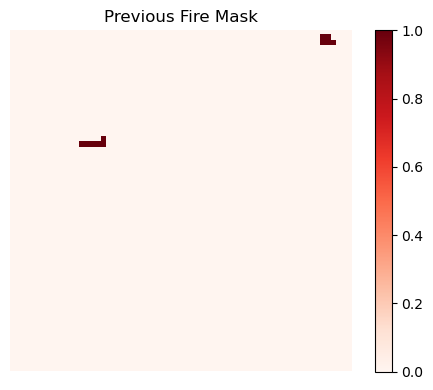

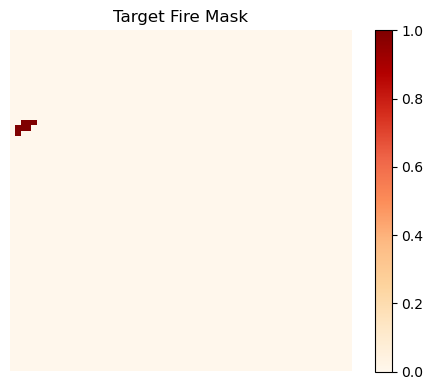

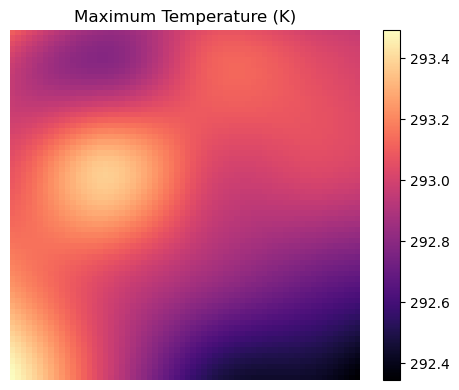

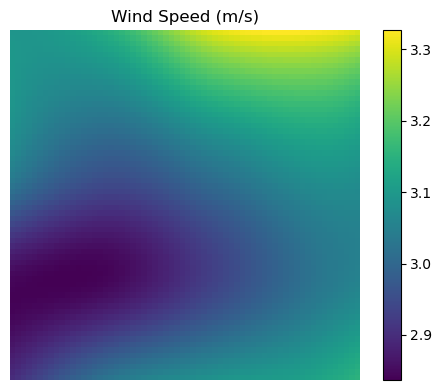

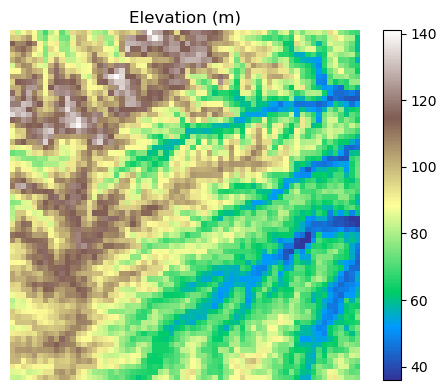

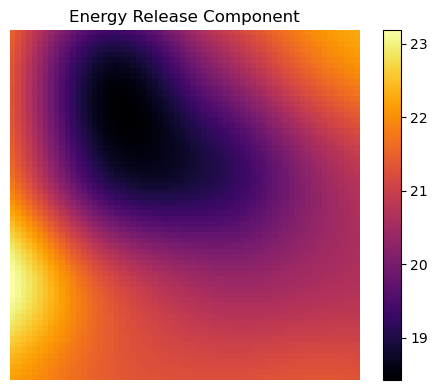

In [16]:
# Load training patches
train_paths = dl.get_tfrecord_paths("train")
patches = list(dl.iter_records(train_paths, max_records=15))

print(f"Training files found: {len(train_paths)}")
print(f"Patches loaded: {len(patches)}")

# Stop if no patches were loaded
if not patches:
    print("No patches found. Check your TFRecord file paths and data loader.")
else:
    # Select a representative patch
    active_patch = patches[0]

    for patch in patches:
        if (patch["FireMask"] == 1).sum() > 10 and (patch["PrevFireMask"] == 1).sum() > 10:
            active_patch = patch
            break

    # Visualize all six channels
    channels = [
        ("PrevFireMask", "Previous Fire Mask", "Reds"),
        ("FireMask", "Target Fire Mask", "OrRd"),
        ("tmmx", "Maximum Temperature (K)", "magma"),
        ("vs", "Wind Speed (m/s)", "viridis"),
        ("elevation", "Elevation (m)", "terrain"),
        ("erc", "Energy Release Component", "inferno")
    ]

    for channel, title, cmap in channels:
        plt.figure(figsize=(5, 4))
        plt.imshow(active_patch[channel], cmap=cmap)
        plt.title(title)
        plt.colorbar()
        plt.axis("off")
        plt.tight_layout()
        plt.savefig(
            os.path.join(fig_dir, f"{channel}.png"),
            dpi=250
        )
        plt.show()

# active_patch = None
# for p in patches:
#     if np.sum(p["FireMask"] == 1.0) > 10 and np.sum(p["PrevFireMask"] == 1.0) > 10:
#         active_patch = p
#         break

# if active_patch is None:
#     active_patch = patches[0]

# channels_to_plot = [
#     ("PrevFireMask", "Day t Active Fire (PrevFireMask)", "Reds"),
#     ("FireMask", "Day t+1 Target Fire (FireMask)", "OrRd"),
#     ("tmmx", "Max Temperature (K)", "magma"),
#     ("vs", "Wind Speed 10m (m/s)", "viridis"),
#     ("elevation", "Elevation (m)", "terrain"),
#     ("erc", "Energy Release Component", "inferno")
# ]

# fig, axes = plt.subplots(2, 3, figsize=(15, 9))
# for idx, (ch, title, cmap) in enumerate(channels_to_plot):
#     ax = axes[idx // 3, idx % 3]
#     im = ax.imshow(active_patch[ch], cmap=cmap)
#     ax.set_title(title, fontsize=12, fontweight="bold")
#     plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
#     ax.axis("off")

# plt.suptitle("Multi-Channel Spatial Representation of Wildfire Spread Event (64x64 km)", fontsize=16, fontweight="bold")
# plt.tight_layout()
# plt.savefig(os.path.join(fig_dir, "multichannel_spatial_patch.png"), dpi=250)
# plt.show()

## 3. Tabular Extraction and Environmental Feature Distributions
We extract pixel-level tabular observations from the audited patches to evaluate distributions and check for anomalies or missing values.


In [17]:
# tabular_df = dl.extract_split_tabular("train", max_patches=15, sample_negatives_ratio=10.0)
# print(f"Extracted {len(tabular_df)} pixel records across 15 patches.")

# features_to_hist = ["tmmx", "tmmn", "sph", "vs", "elevation", "erc", "NDVI", "pdsi"]

# fig, axes = plt.subplots(2, 4, figsize=(16, 7))
# axes = axes.flatten()

# for idx, col in enumerate(features_to_hist):
#     sns.histplot(tabular_df[col], kde=True, ax=axes[idx], color="teal", bins=30)
#     axes[idx].set_title(f"Distribution of {col}", fontsize=11, fontweight="bold")
#     axes[idx].grid(True, alpha=0.3)

# plt.suptitle("Environmental Feature Distributions Across Wildfire Samples", fontsize=15, fontweight="bold")
# plt.tight_layout()
# plt.savefig(os.path.join(fig_dir, "feature_distributions.png"), dpi=250)
# plt.show()








import os

search_dir = os.path.abspath("..")

for root, dirs, files in os.walk(os.path.dirname(search_dir)):
    dirs[:] = [d for d in dirs if d not in [".git", ".venv", "node_modules"]]

    for file in files:
        if file.endswith((".tfrecord", ".tfrecords", ".tfrecord.gz")):
            print(os.path.join(root, file))


import os

for folder in ["../data", "../data/raw", "../data/processed"]:
    print(f"\n{folder}:")
    print(os.listdir(folder))

# tabular_df = dl.extract_split_tabular("train", max_patches=15, sample_negatives_ratio=10.0)
# print(f"Extracted {len(tabular_df)} pixel records.")

# features = ["tmmx", "tmmn", "sph", "vs", "elevation", "erc", "NDVI", "pdsi"]

# for feature in features:
#     plt.figure(figsize=(6, 4))
#     sns.histplot(tabular_df[feature], kde=True, bins=30, color="teal")
#     plt.title(f"Distribution of {feature}")
#     plt.grid(alpha=0.3)
#     plt.tight_layout()
#     plt.show()
#     plt.close()



/Users/vanshikayadav/Desktop/AMLDL/TensorTitans_SectionC/data/raw/archive/next_day_wildfire_spread_train_00.tfrecord
/Users/vanshikayadav/Desktop/AMLDL/TensorTitans_SectionC/data/raw/archive/next_day_wildfire_spread_train_01.tfrecord
/Users/vanshikayadav/Desktop/AMLDL/TensorTitans_SectionC/data/raw/archive/next_day_wildfire_spread_eval_00.tfrecord
/Users/vanshikayadav/Desktop/AMLDL/TensorTitans_SectionC/data/raw/archive/next_day_wildfire_spread_eval_01.tfrecord
/Users/vanshikayadav/Desktop/AMLDL/TensorTitans_SectionC/data/raw/archive/next_day_wildfire_spread_train_07.tfrecord
/Users/vanshikayadav/Desktop/AMLDL/TensorTitans_SectionC/data/raw/archive/next_day_wildfire_spread_train_06.tfrecord
/Users/vanshikayadav/Desktop/AMLDL/TensorTitans_SectionC/data/raw/archive/next_day_wildfire_spread_train_10.tfrecord
/Users/vanshikayadav/Desktop/AMLDL/TensorTitans_SectionC/data/raw/archive/next_day_wildfire_spread_train_11.tfrecord
/Users/vanshikayadav/Desktop/AMLDL/TensorTitans_SectionC/data/raw/

## 4. Correlation Structure Among Meteorological and Terrain Predictors
Understanding inter-feature collinearity informs feature selection, regularisation, and prevents redundant splits in gradient boosted trees.


In [18]:
corr_cols = dl.FEATURE_NAMES
corr_matrix = tabular_df[corr_cols].corr()

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, 
    mask=mask,
    annot=True, 
    fmt=".2f", 
    cmap="coolwarm", 
    vmin=-1, 
    vmax=1,
    square=True,
    linewidths=0.5
)
plt.title("Correlation Matrix of Environmental Input Features", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, "feature_correlation_heatmap.png"), dpi=250)
plt.show()


NameError: name 'tabular_df' is not defined

## 5. Physical Contrast: Burned vs. Unburned Pixel Environments
We test whether environmental variables exhibit statistically distinct conditions for pixels that ignite on day $t+1$ versus pixels that remain unburned.


In [ ]:
contrast_cols = ["tmmx", "sph", "vs", "erc", "elevation", "NDVI", "PrevFireMask"]
contrast_summary = tabular_df.groupby("FireMask")[contrast_cols].agg(["mean", "std"]).T
contrast_summary.columns = ["Unburned (0.0)", "Burned (1.0)"]
display(contrast_summary)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
plot_vars = ["tmmx", "sph", "erc", "vs"]
var_titles = ["Max Temp (K)", "Specific Humidity (kg/kg)", "Energy Release Component", "Wind Speed (m/s)"]

for idx, (v, title) in enumerate(zip(plot_vars, var_titles)):
    sns.boxplot(x="FireMask", y=v, data=tabular_df, ax=axes[idx], palette=["skyblue", "crimson"], hue="FireMask", legend=False)
    axes[idx].set_title(title, fontweight="bold")
    axes[idx].set_xticklabels(["Unburned (0)", "Burned (1)"])
    axes[idx].grid(True, alpha=0.3)

plt.suptitle("Environmental Contrast: Burned vs. Unburned Terrain Conditions", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, "burned_vs_unburned_contrast.png"), dpi=250)
plt.show()

## 6. Data Quality and Modeling Implications
- **Missing Values**: Zero null or unrecorded values in the 11 continuous features.
- **Label Uncertainty**: Filtered all pixels with `FireMask == -1.0` to prevent unobserved satellite obscuration from contaminating training.
- **Physical Coherence**: Burned pixels show elevated maximum temperature (`tmmx`), higher fuel dryness (`erc`), lower specific humidity (`sph`), and strong proximity to previous-day fire perimeters (`PrevFireMask`).
